# 🚗 Used Car Price Segment Prediction (CarDekho Dataset)
### Data Science & Machine Learning Project (Python)

**Dataset:** Vehicle dataset from CarDekho (`Car details v3.csv`) – Kaggle
🔗 https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho

**Problem Statement:** Ek used car ki details (age, km chalna, engine, fuel, brand, etc.) dekh kar predict karna ki wo car **Low / Mid / High** price segment me aayegi.
Price ek continuous number hai, isliye hum `selling_price` ko 3 barabar classes me todenge (classification problem).

---
### Project Objectives (5)
Saare objectives **classification models** (KNN, Naive Bayes, Random Forest, Logistic Regression) se investigate kiye gaye hain. Target: price class **Low / Mid / High**.

| # | Objective |
|---|---|
| 1 | Kaun se features models ke hisaab se price class predict karne me sabse important hain? |
| 2 | Sirf car age aur km_driven se models class kitni sahi predict kar paate hain? |
| 3 | Fuel type aur transmission model ki accuracy me kitna yogdan dete hain? |
| 4 | Owner count aur seller type model ki accuracy me kitna yogdan dete hain? |
| 5 | KNN, Naive Bayes, Random Forest aur Logistic Regression me se **best classification model** kaun sa hai? |

### Notebook ka flow
1. Libraries & data load
2. Data cleaning (duplicates, inconsistent data, missing values, outliers)
3. Feature engineering (nayi columns)
4. Exploratory Data Analysis (EDA)
5. Class-wise EDA (price class ke hisaab se charts)
6. Encoding, train-test split aur scaling
7. Machine Learning models (4 classification models)
8. Model evaluation (best model)
9. Objectives 1 to 5 (classification models se investigation)
10. Findings, conclusion aur recommendations

## 1. Libraries import karna aur data load karna

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Libraries import ho gayi")

Libraries import ho gayi


In [2]:
# Kaggle se download ki hui file isi notebook wale folder me rakho.
# Kaggle/Colab me chala rahe ho to path badal lena, jaise:
# "/kaggle/input/vehicle-dataset-from-cardekho/Car details v3.csv"
df = pd.read_csv("Car details v3.csv")

print("Rows aur Columns:", df.shape)
df.head()

Rows aur Columns: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
# Data ki basic jaankari
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [4]:
# Numeric columns ka summary
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


## 2. Data Cleaning

Is section me hum 4 kaam karenge:
1. **Duplicate rows** hatana
2. **Inconsistent data** theek karna (text me chhupe numbers, alag-alag units, galat values)
3. **Missing values** bharna
4. **Outliers** ko sambhalna

### 2.1 Duplicate rows

In [5]:
print("Duplicate rows (pehle):", df.duplicated().sum())

df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Duplicate rows (baad me):", df.duplicated().sum())
print("Naya shape:", df.shape)

Duplicate rows (pehle): 1202
Duplicate rows (baad me): 0
Naya shape: (6926, 13)


### 2.2 Inconsistent data

Pehle dekhte hain kaun si columns me dikkat hai.

In [6]:
# Categorical columns ki unique values dekhte hain
print("Owner:\n", df["owner"].value_counts(), "\n")
print("Fuel:\n", df["fuel"].value_counts(), "\n")
print("Seller type:\n", df["seller_type"].value_counts(), "\n")
print("Transmission:\n", df["transmission"].value_counts())

Owner:
 owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64 

Fuel:
 fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64 

Seller type:
 seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64 

Transmission:
 transmission
Manual       6342
Automatic     584
Name: count, dtype: int64


In [7]:
# mileage, engine, max_power, torque columns text me hain (e.g. "23.4 kmpl", "1248 CC", "74 bhp")
print(df[["mileage", "engine", "max_power", "torque"]].head(8))

# mileage me do alag units hain
print("\nkmpl wale rows :", df["mileage"].astype(str).str.contains("kmpl").sum())
print("km/kg wale rows:", df["mileage"].astype(str).str.contains("km/kg").sum())

# torque me Nm aur kgm dono units hain
print("\ntorque me Nm wale rows :", df["torque"].astype(str).str.lower().str.contains("nm").sum())
print("torque me kgm wale rows:", df["torque"].astype(str).str.lower().str.contains("kgm").sum())

      mileage   engine   max_power                    torque
0   23.4 kmpl  1248 CC      74 bhp            190Nm@ 2000rpm
1  21.14 kmpl  1498 CC  103.52 bhp       250Nm@ 1500-2500rpm
2   17.7 kmpl  1497 CC      78 bhp     12.7@ 2,700(kgm@ rpm)
3   23.0 kmpl  1396 CC      90 bhp  22.4 kgm at 1750-2750rpm
4   16.1 kmpl  1298 CC    88.2 bhp     11.5@ 4,500(kgm@ rpm)
5  20.14 kmpl  1197 CC   81.86 bhp         113.75nm@ 4000rpm
6  17.3 km/kg  1061 CC    57.5 bhp      7.8@ 4,500(kgm@ rpm)
7   16.1 kmpl   796 CC      37 bhp             59Nm@ 2500rpm

kmpl wale rows : 6631
km/kg wale rows: 87

torque me Nm wale rows : 6227
torque me kgm wale rows: 481


**Problems jo mili:**
- `mileage`, `engine`, `max_power`, `torque` text me hain, number me nahi.
- `mileage` ka unit kisi me `kmpl` hai, kisi me `km/kg` (CNG/LPG cars).
- `torque` kisi me **Nm** me hai, kisi me **kgm** me. Dono ko ek unit (Nm) me lana hoga (1 kgm = 9.80665 Nm).
- `owner` me "Test Drive Car" wali rows hain, jo normal used cars nahi hain.
- `max_power` aur kuch columns me `0` jaisi galat value ho sakti hai.
- Kuch rows me torque "kgm" likha hai par number asal me Nm me hai (e.g. `145@ 4,100(kgm@ rpm)`). Aisi values ko hum convert nahi karenge.

In [8]:
# Function 1: text me se pehla number nikalna. Example: "23.4 kmpl" -> 23.4
def get_number(text):
    if pd.isnull(text):
        return np.nan
    number = ""
    for ch in str(text):
        if ch.isdigit() or ch == ".":
            number = number + ch
        elif number != "":
            break                    # number khatam ho gaya, ruk jao
    if number == "" or number == ".":
        return np.nan
    return float(number)


# Function 2: torque ko Nm me badalna
def get_torque_nm(text):
    value = get_number(text)
    if pd.isnull(value):
        return np.nan
    text = str(text).lower()
    if "nm" in text:
        return value                 # pehle se Nm me hai
    if "kgm" in text:
        if value > 50:
            return value             # kgm me 50 se zyada possible nahi, to ye asal me Nm hi hai (dataset ki galti)
        return value * 9.80665       # kgm ko Nm me convert
    return value                     # unit nahi likha hai, to Nm maan lete hain


# Test karke dekho
print(get_number("23.4 kmpl"))
print(get_number("1248 CC"))
print(get_torque_nm("190Nm@ 2000rpm"))
print(get_torque_nm("22.4 kgm at 1750-2750rpm"))

23.4
1248.0
190.0
219.66895999999997


In [9]:
# "Test Drive Car" wali rows hatao
print("Test Drive Car rows:", (df["owner"] == "Test Drive Car").sum())
df = df[df["owner"] != "Test Drive Car"]

# Text columns ko numbers me badlo
df["mileage"] = df["mileage"].apply(get_number)
df["engine"] = df["engine"].apply(get_number)
df["max_power"] = df["max_power"].apply(get_number)
df["torque_nm"] = df["torque"].apply(get_torque_nm)

# Purani text wali torque column hata do
df = df.drop(columns=["torque"])

# 0 value in columns me galat hai (engine ya power 0 nahi ho sakta), isko missing (NaN) maan lo
for col in ["mileage", "engine", "max_power"]:
    print(col, "me 0 values:", (df[col] == 0).sum())
    df.loc[df[col] == 0, col] = np.nan

df = df.reset_index(drop=True)
df[["mileage", "engine", "max_power", "torque_nm"]].describe()

Test Drive Car rows: 5


mileage me 0 values: 15
engine me 0 values: 0
max_power me 0 values: 3


,mileage,engine,max_power,torque_nm
count,6698.000000,6713.000000,6712.000000,6712.000000
mean,19.510809,1430.662446,87.710610,170.739205
std,3.947586,493.594859,31.658543,84.373904
min,9.000000,624.000000,32.800000,47.071920
25%,16.800000,1197.000000,67.100000,110.000000
50%,19.490000,1248.000000,81.830000,160.000000
75%,22.540000,1498.000000,100.000000,200.055660
max,42.000000,3604.000000,400.000000,789.000000


### 2.3 Missing values

mileage      223
engine       208
max_power    209
seats        208
torque_nm    209
dtype: int64


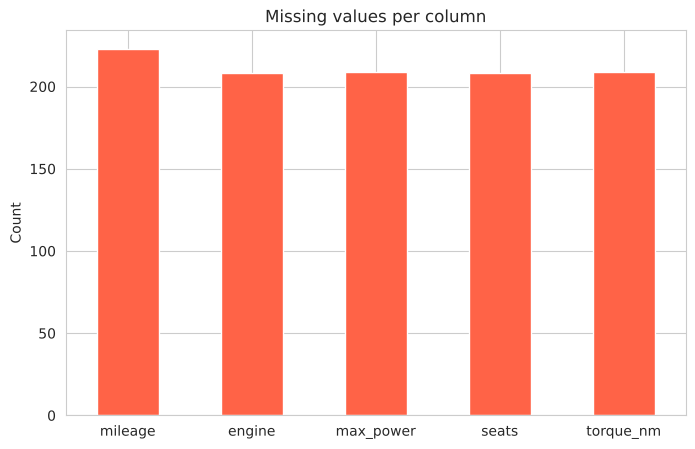

In [10]:
missing = df.isnull().sum()
print(missing[missing > 0])

# Missing values ka bar chart
missing[missing > 0].plot(kind="bar", color="tomato")
plt.title("Missing values per column")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [11]:
# Numeric columns -> median se bharo (outliers se kam asar padta hai)
for col in ["mileage", "engine", "max_power", "torque_nm"]:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# seats -> sabse zyada aane wali value (mode) se bharo
df["seats"] = df["seats"].fillna(df["seats"].mode()[0])
df["seats"] = df["seats"].astype(int)

print("Ab missing values:", df.isnull().sum().sum())

Ab missing values: 0


> **Note:** Yahan median poore data se nikala hai (simple rakhne ke liye). Strictly, median sirf train data se nikalna chahiye, par yahan sirf ~3% rows missing thi, isliye asar bahut chhota hai.

### 2.4 Outliers

`km_driven` aur `selling_price` me kuch bahut bade values ho sakte hain. Boxplot se dekhte hain.

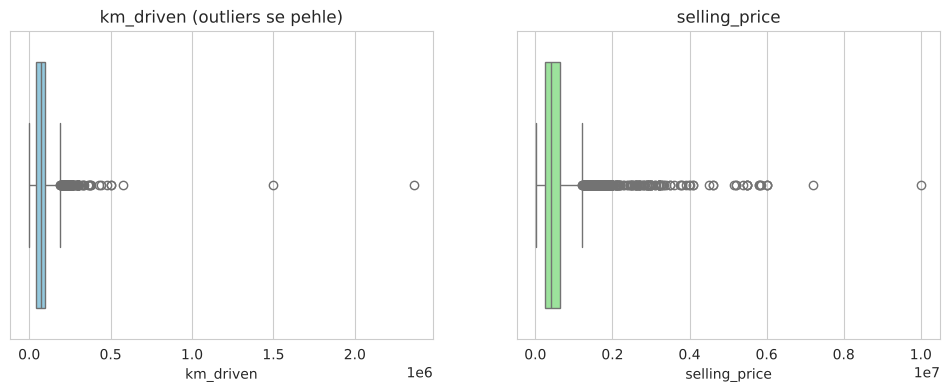

Sabse zyada km_driven: 2360457


In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["km_driven"], color="skyblue")
plt.title("km_driven (outliers se pehle)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["selling_price"], color="lightgreen")
plt.title("selling_price")

plt.show()
print("Sabse zyada km_driven:", df["km_driven"].max())

In [13]:
# km_driven ko 99th percentile par cap kar do (bahut extreme values ko control karne ke liye)
limit = df["km_driven"].quantile(0.99)
print("99th percentile limit:", limit)

df["km_driven"] = df["km_driven"].clip(upper=limit)
print("Cap ke baad max km_driven:", df["km_driven"].max())

# selling_price ko hum cap nahi kar rahe, kyunki aage hum use 3 equal classes me todenge
# (extreme price waali luxury cars bas "High" class me chali jayengi)

99th percentile limit: 239890.2000000001
Cap ke baad max km_driven: 239890.2000000001


## 3. Feature Engineering

Purane columns se nayi, zyada kaam ki columns banate hain:

| New column | Kaise bana | Kyun useful |
|---|---|---|
| `brand` | `name` ka pehla word | Brand price ko bahut affect karta hai |
| `car_age` | latest year − year | Year se zyada seedha "kitni purani" |
| `km_per_year` | km_driven / (car_age + 1) | Car kitni heavily use hui |
| `power_per_cc` | max_power / engine | Engine kitna efficient/powerful hai |
| `price_lakh` | selling_price / 1,00,000 | Charts padhne me aasan |
| `price_class` | selling_price ko 3 barabar parts me | **Target (Low / Mid / High)** |

In [14]:
# 1) Brand = name ka pehla word
df["brand"] = df["name"].str.split().str[0]
df.loc[df["brand"] == "Land", "brand"] = "Land Rover"      # "Land Rover" 2 words ka hai

# 2) Car age (dataset me sabse nayi car ka year = latest year)
latest_year = df["year"].max()
print("Latest year in data:", latest_year)
df["car_age"] = latest_year - df["year"]

# 3) Km per year
df["km_per_year"] = df["km_driven"] / (df["car_age"] + 1)

# 4) Power per cc
df["power_per_cc"] = df["max_power"] / df["engine"]

# 5) Price lakh me
df["price_lakh"] = df["selling_price"] / 100000

df[["name", "brand", "year", "car_age", "km_driven", "km_per_year", "power_per_cc"]].head()

Latest year in data: 2020


,name,brand,year,car_age,km_driven,km_per_year,power_per_cc
0,Maruti Swift Dzire VDI,Maruti,2014,6,145500.0,20785.714286,0.059295
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,6,120000.0,17142.857143,0.069105
2,Honda City 2017-2020 EXi,Honda,2006,14,140000.0,9333.333333,0.052104
3,Hyundai i20 Sportz Diesel,Hyundai,2010,10,127000.0,11545.454545,0.064470
4,Maruti Swift VXI BSIII,Maruti,2007,13,120000.0,8571.428571,0.067951


In [15]:
# 6) TARGET: price ko 3 barabar classes me todo (qcut = har class me lagbhag barabar cars)
df["price_class"] = pd.qcut(df["selling_price"], q=3, labels=["Low", "Mid", "High"])

# Har class ki price range dekhte hain
class_summary = df.groupby("price_class", observed=True)["price_lakh"].agg(["min", "max", "count"])
class_summary.columns = ["Min price (lakh)", "Max price (lakh)", "Cars"]
class_summary

,Min price (lakh),Max price (lakh),Cars
price_class,,,
Low,0.29999,3.0,2462
Mid,3.02000,5.5,2210
High,5.51000,100.0,2249


Matlab agar car ka price **Low** class ki upper limit se kam hai to wo budget car hai, **Mid** me beech wali, aur **High** me premium cars aati hain.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target (price) ka distribution

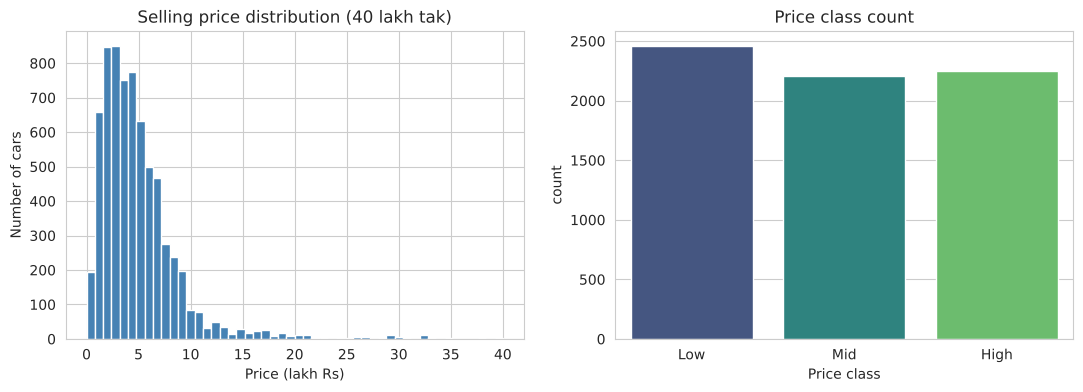

price_class
Low     2462
High    2249
Mid     2210
Name: count, dtype: int64


In [16]:
plt.figure(figsize=(13, 4))

# Price histogram (40 lakh tak, taaki chart saaf dikhe)
plt.subplot(1, 2, 1)
plt.hist(df["price_lakh"], bins=50, range=(0, 40), color="steelblue", edgecolor="white")
plt.title("Selling price distribution (40 lakh tak)")
plt.xlabel("Price (lakh Rs)")
plt.ylabel("Number of cars")

# Class balance
plt.subplot(1, 2, 2)
sns.countplot(x="price_class", data=df, order=["Low", "Mid", "High"], palette="viridis")
plt.title("Price class count")
plt.xlabel("Price class")

plt.show()
print(df["price_class"].value_counts())

### 4.2 Categorical columns

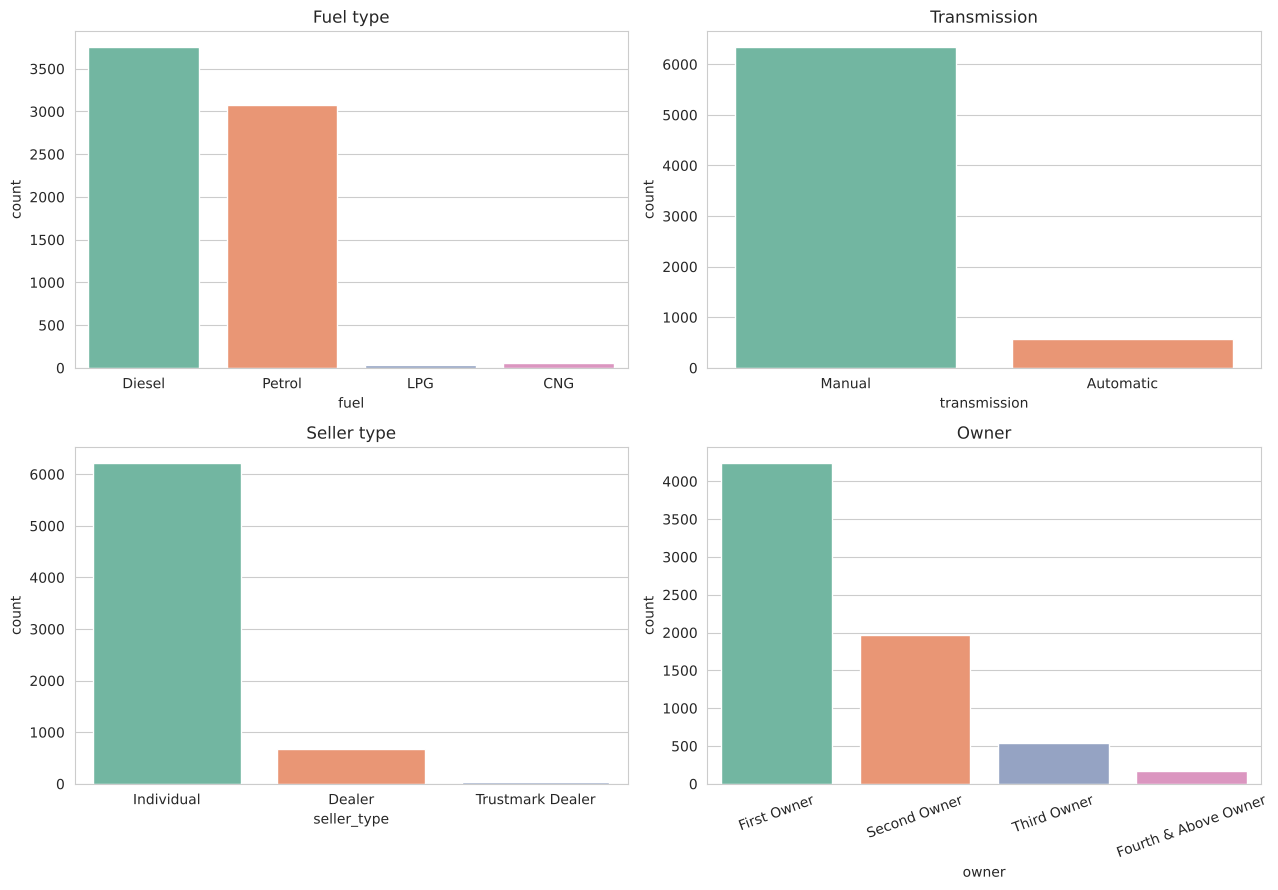

In [17]:
plt.figure(figsize=(13, 9))

plt.subplot(2, 2, 1)
sns.countplot(x="fuel", data=df, palette="Set2")
plt.title("Fuel type")

plt.subplot(2, 2, 2)
sns.countplot(x="transmission", data=df, palette="Set2")
plt.title("Transmission")

plt.subplot(2, 2, 3)
sns.countplot(x="seller_type", data=df, palette="Set2")
plt.title("Seller type")

plt.subplot(2, 2, 4)
sns.countplot(x="owner", data=df, palette="Set2")
plt.title("Owner")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 4.3 Numeric columns ka distribution

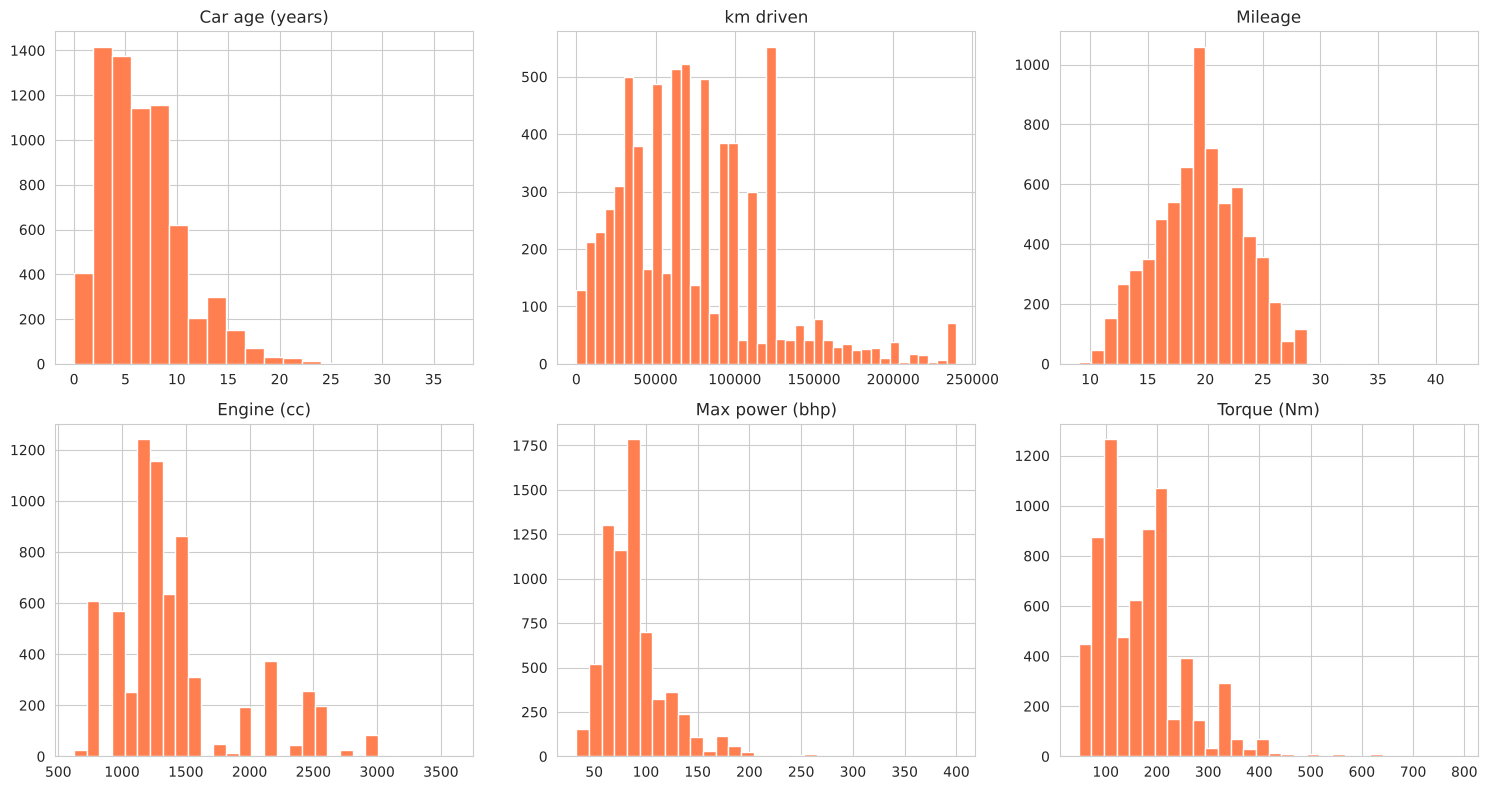

In [18]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.hist(df["car_age"], bins=20, color="coral", edgecolor="white")
plt.title("Car age (years)")

plt.subplot(2, 3, 2)
plt.hist(df["km_driven"], bins=40, color="coral", edgecolor="white")
plt.title("km driven")

plt.subplot(2, 3, 3)
plt.hist(df["mileage"], bins=30, color="coral", edgecolor="white")
plt.title("Mileage")

plt.subplot(2, 3, 4)
plt.hist(df["engine"], bins=30, color="coral", edgecolor="white")
plt.title("Engine (cc)")

plt.subplot(2, 3, 5)
plt.hist(df["max_power"], bins=30, color="coral", edgecolor="white")
plt.title("Max power (bhp)")

plt.subplot(2, 3, 6)
plt.hist(df["torque_nm"], bins=30, color="coral", edgecolor="white")
plt.title("Torque (Nm)")

plt.tight_layout()
plt.show()

### 4.4 Top 10 brands

brand
Maruti        2165
Hyundai       1267
Mahindra       723
Tata           647
Honda          361
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     173
Name: count, dtype: int64


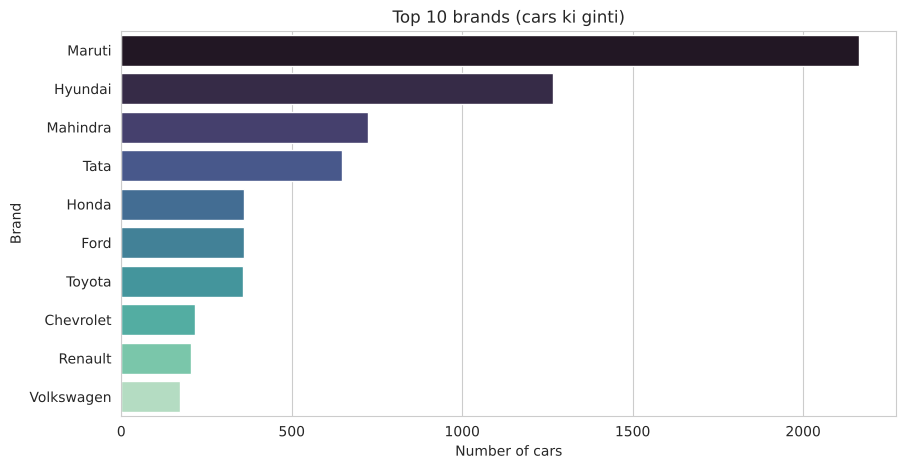

In [19]:
top10 = df["brand"].value_counts().head(10)
print(top10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10.values, y=top10.index, palette="mako")
plt.title("Top 10 brands (cars ki ginti)")
plt.xlabel("Number of cars")
plt.ylabel("Brand")
plt.show()

### 4.5 Correlation Heatmap

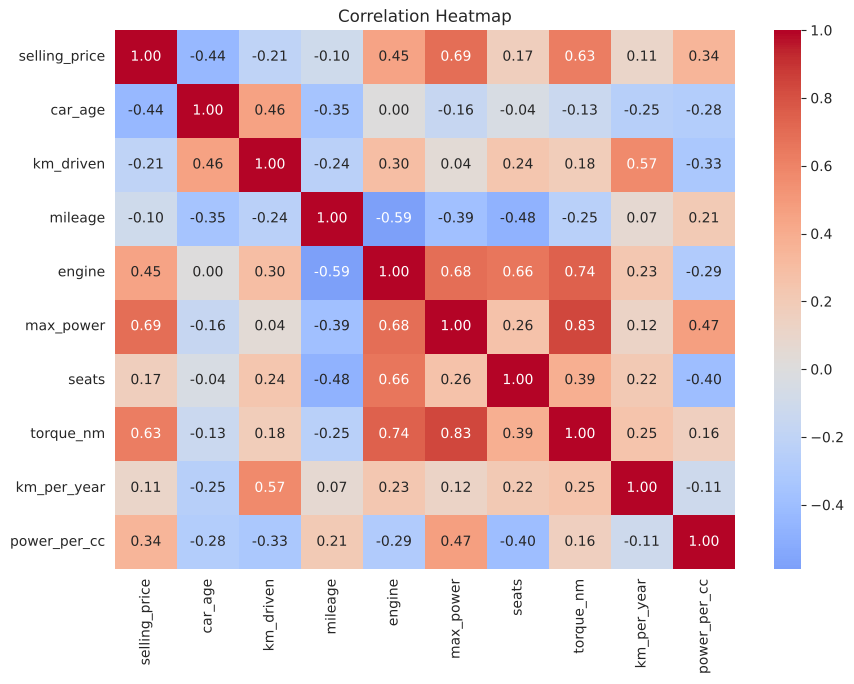

In [20]:
num_cols = ["selling_price", "car_age", "km_driven", "mileage", "engine",
            "max_power", "seats", "torque_nm", "km_per_year", "power_per_cc"]

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**EDA se pata chala:**
- Price right-skewed hai: median price lagbhag **4 lakh** hai, par kuch luxury cars 1 crore tak jaati hain.
- Teeno classes lagbhag barabar hain: **Low** (3 lakh tak), **Mid** (3 se 5.5 lakh), **High** (5.5 lakh se upar). Isliye class imbalance ki dikkat nahi.
- Zyadatar cars **Diesel (3755)** ya **Petrol (3077)** hain, **Manual (6342)** hain aur **First Owner (4242)** ki hain.
- Lagbhag 90% cars **Individual** sellers ki hain (6218 me se).
- Top brands: **Maruti (2165)** aur **Hyundai (1267)** sabse aage hain.
- Heatmap me max_power aur torque_nm ka aapas me correlation **0.83** hai, yaani ye dono saath badhte hain aur inka asar overlap karta hai.

## 5. Class-wise EDA (price class ke hisaab se)

Hamara target ek **class** hai: **Low / Mid / High**. Pehle charts se dekhte hain ki alag-alag features har class me kaise badalte hain. Iske baad Section 9 me hum isi baat ko **classification models** se test karenge.

### 5.1 Features vs price class
Pehle dekhte hain ki har class me features ka average kya hai, phir boxplot se compare karenge.

In [21]:
features = ["car_age", "km_driven", "mileage", "engine", "max_power",
            "seats", "torque_nm", "km_per_year", "power_per_cc"]

# Har price class me features ka average
class_mean = df.groupby("price_class", observed=True)[features].mean().round(2)
class_mean

,car_age,km_driven,mileage,engine,max_power,seats,torque_nm,km_per_year,power_per_cc
price_class,,,,,,,,,
Low,10.00,85366.55,19.00,1216.49,70.79,5.15,126.12,8419.53,0.06
Mid,5.67,73489.02,20.14,1409.94,84.51,5.42,163.75,11137.21,0.06
High,3.74,58933.96,19.44,1668.59,108.83,5.72,225.46,12311.70,0.07


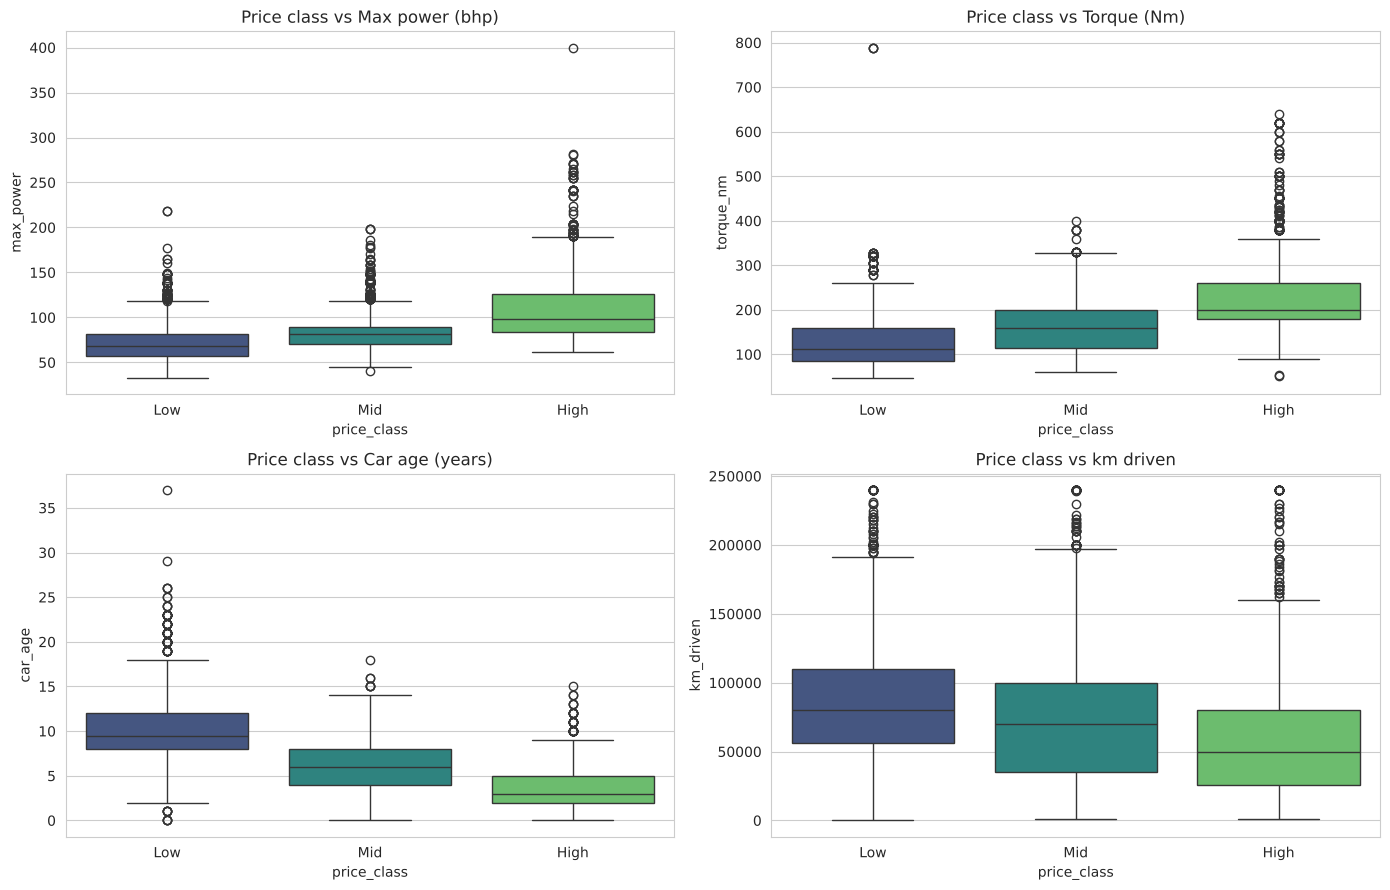

In [22]:
class_order = ["Low", "Mid", "High"]

plt.figure(figsize=(14, 9))

plt.subplot(2, 2, 1)
sns.boxplot(x="price_class", y="max_power", data=df, order=class_order, palette="viridis")
plt.title("Price class vs Max power (bhp)")

plt.subplot(2, 2, 2)
sns.boxplot(x="price_class", y="torque_nm", data=df, order=class_order, palette="viridis")
plt.title("Price class vs Torque (Nm)")

plt.subplot(2, 2, 3)
sns.boxplot(x="price_class", y="car_age", data=df, order=class_order, palette="viridis")
plt.title("Price class vs Car age (years)")

plt.subplot(2, 2, 4)
sns.boxplot(x="price_class", y="km_driven", data=df, order=class_order, palette="viridis")
plt.title("Price class vs km driven")

plt.tight_layout()
plt.show()

car_age        -0.64
km_driven      -0.24
mileage         0.05
km_per_year     0.24
seats           0.24
power_per_cc    0.25
engine          0.38
torque_nm       0.49
max_power       0.50
Name: class_num, dtype: float64


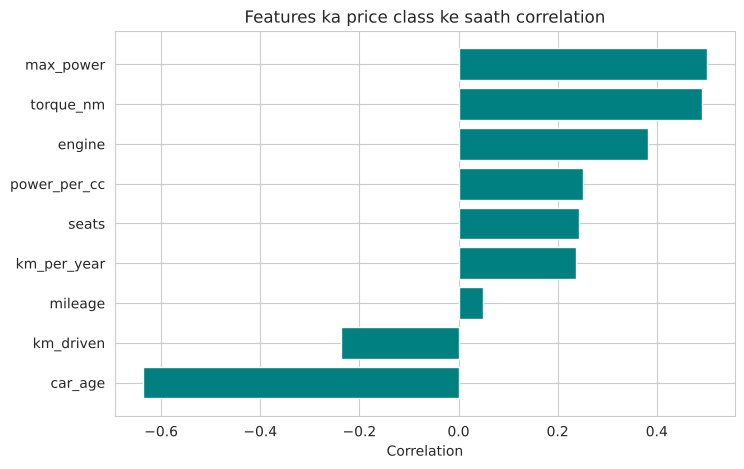

In [23]:
# Class ko number me badlo (Low=0, Mid=1, High=2), phir correlation nikalo
df["class_num"] = df["price_class"].map({"Low": 0, "Mid": 1, "High": 2})

corr_class = df[features + ["class_num"]].corr()["class_num"]
corr_class = corr_class.drop("class_num")      # class_num ka apne aap se correlation hata do
corr_class = corr_class.sort_values()
print(corr_class.round(2))

plt.figure(figsize=(8, 5))
plt.barh(corr_class.index, corr_class.values, color="teal")
plt.title("Features ka price class ke saath correlation")
plt.xlabel("Correlation")
plt.show()

**Observation (5.1):**
- Jaise-jaise class **Low se High** ki taraf jaati hai, **max_power** (70.8 se 108.8 bhp), **torque** (126 se 225 Nm) aur **engine** (1216 se 1669 cc) ka average badhta jaata hai.
- **car_age** sabse bada fark deta hai: Low class ki cars ki average age **10 saal**, Mid ki **5.7 saal** aur High ki **3.7 saal** hai. Class ke saath iska correlation bhi sabse strong (negative) **−0.64** hai.
- Positive side par: **max_power (0.50)**, **torque_nm (0.49)** aur **engine (0.38)**. km_driven ka asar negative aur kam hai (−0.24), aur mileage ka lagbhag koi rishta nahi (0.05).
- Random Forest ka feature importance (Section 9.1) bhi yahi batata hai: car_age sabse upar, phir torque_nm, max_power aur km_driven.
- Dhyan rakho: max_power, torque aur engine aapas me correlated hain, isliye inka asar overlap karta hai.

### 5.2 Car age aur km_driven vs price class
Car ko age aur km ke groups me baant kar dekhte hain ki har group me Low / Mid / High cars ka kitna % hai.

price_class   Low   Mid  High
age_group                    
0-3 yrs       4.9  28.6  66.4
4-6 yrs      16.2  42.7  41.1
7-10 yrs     53.0  36.9  10.1
10+ yrs      90.2   7.7   2.1


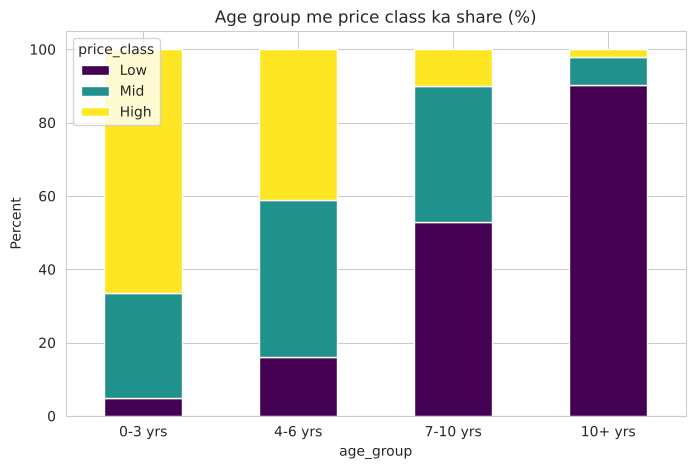

In [24]:
# Age ko groups me baanto
def age_group(age):
    if age <= 3:
        return "0-3 yrs"
    elif age <= 6:
        return "4-6 yrs"
    elif age <= 10:
        return "7-10 yrs"
    else:
        return "10+ yrs"

df["age_group"] = df["car_age"].apply(age_group)

# Har age group me class ka share (%)
age_share = pd.crosstab(df["age_group"], df["price_class"], normalize="index") * 100
age_share = age_share.loc[["0-3 yrs", "4-6 yrs", "7-10 yrs", "10+ yrs"], class_order]
print(age_share.round(1))

age_share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Age group me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

price_class   Low   Mid  High
km_group                     
0-30k km     14.2  34.7  51.1
30-60k km    33.0  29.7  37.3
60-100k km   43.8  31.5  24.7
100k+ km     46.0  32.7  21.3


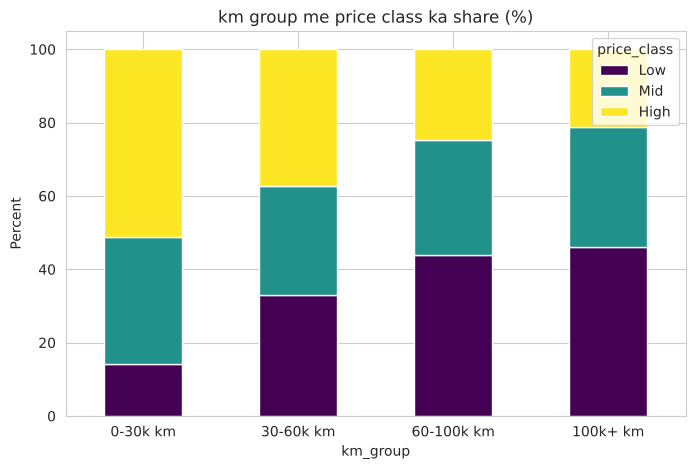

In [25]:
# km_driven ko groups me baanto
def km_group(km):
    if km <= 30000:
        return "0-30k km"
    elif km <= 60000:
        return "30-60k km"
    elif km <= 100000:
        return "60-100k km"
    else:
        return "100k+ km"

df["km_group"] = df["km_driven"].apply(km_group)

km_share = pd.crosstab(df["km_group"], df["price_class"], normalize="index") * 100
km_share = km_share.loc[["0-30k km", "30-60k km", "60-100k km", "100k+ km"], class_order]
print(km_share.round(1))

km_share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("km group me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

**Observation (5.2):**
- Age badhne par class tezi se **High se Low** ki taraf shift hoti hai: **0-3 saal** wali cars me **66.4% High** hain, jabki **10+ saal** wali cars me **90.2% Low** hain (sirf 2.1% High).
- **4-6 saal** wali cars zyadatar Mid (42.7%) aur High (41.1%) me hain, aur **7-10 saal** wali zyadatar Low (53.0%) me.
- km_driven ka asar age se kam hai: **0-30k km** wali cars me **51.1% High** hain, jabki **100k+ km** me sirf **21.3% High**. 60-100k aur 100k+ km me Low ka share lagbhag same hai (43.8% aur 46.0%).
- Dhyan rakho: zyada km wali cars aksar purani bhi hoti hain (age aur km ka correlation 0.46), isliye km ka asar thoda age ke saath mila hua hai.

### 5.3 Fuel type aur transmission vs price class

price_class   Low   Mid  High
fuel                         
CNG          46.4  53.6   0.0
Diesel       23.4  31.5  45.0
LPG          94.7   5.3   0.0
Petrol       49.5  32.3  18.2


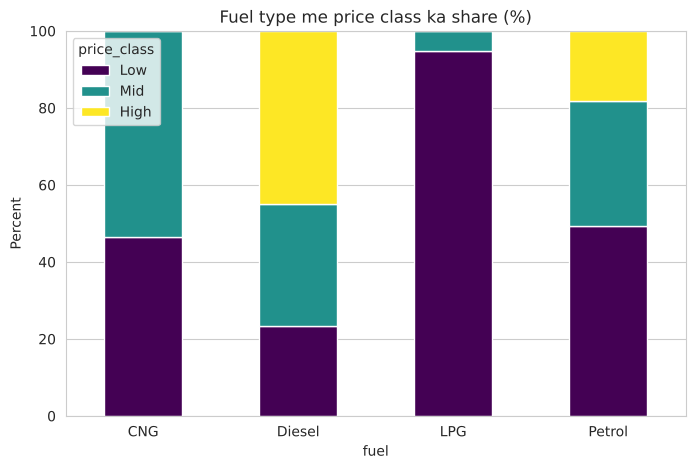

In [26]:
fuel_share = pd.crosstab(df["fuel"], df["price_class"], normalize="index") * 100
fuel_share = fuel_share[class_order]
print(fuel_share.round(1))

fuel_share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Fuel type me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

price_class    Low   Mid  High
transmission                  
Automatic      6.4  19.7  74.0
Manual        38.2  33.1  28.7


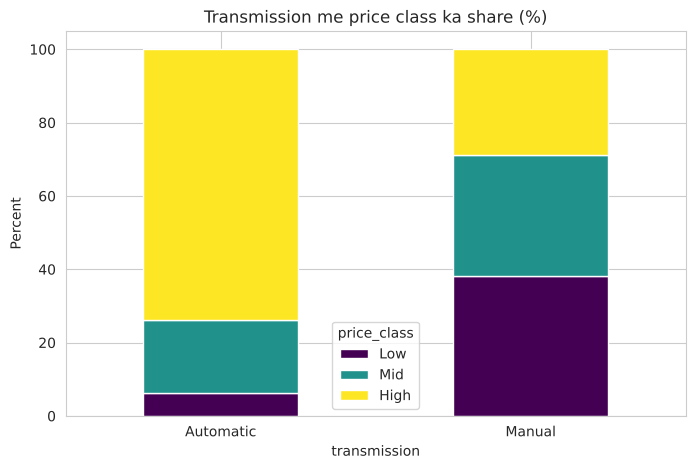

In [27]:
trans_share = pd.crosstab(df["transmission"], df["price_class"], normalize="index") * 100
trans_share = trans_share[class_order]
print(trans_share.round(1))

trans_share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Transmission me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

**Observation (5.3):**
- **Automatic** cars me **74.0%** High hain, jabki **Manual** me sirf 28.7% High aur 38.2% Low.
- **Diesel** cars me **45.0%** High hain, jabki **Petrol** me sirf **18.2%** High (aur 49.5% Low).
- **CNG** (56 cars) me koi car High nahi hai (0%), aur **LPG** (38 cars) me 94.7% cars Low hain. In dono me cars bahut kam hain, isliye inke % par zyada bharosa nahi karna chahiye.
- Dhyan rakho: automatic aur diesel cars aksar badi, powerful aur nayi bhi hoti hain, isliye ye fark sirf fuel ya transmission ki wajah se nahi hai.

### 5.4 Owner count aur seller type vs price class

price_class            Low   Mid  High
owner                                 
First Owner           23.5  33.4  43.1
Second Owner          49.9  31.4  18.7
Third Owner           66.4  24.8   8.8
Fourth & Above Owner  72.8  24.3   3.0


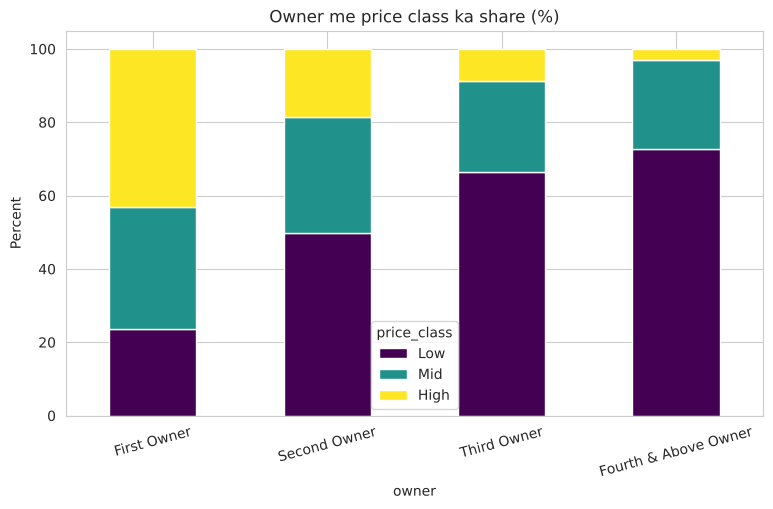

In [28]:
owner_order = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]

owner_share = pd.crosstab(df["owner"], df["price_class"], normalize="index") * 100
owner_share = owner_share.loc[owner_order, class_order]
print(owner_share.round(1))

owner_share.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis")
plt.title("Owner me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=15)
plt.show()

price_class        Low   Mid  High
seller_type                       
Dealer            12.6  30.0  57.4
Individual        38.2  32.2  29.6
Trustmark Dealer   3.7  25.9  70.4


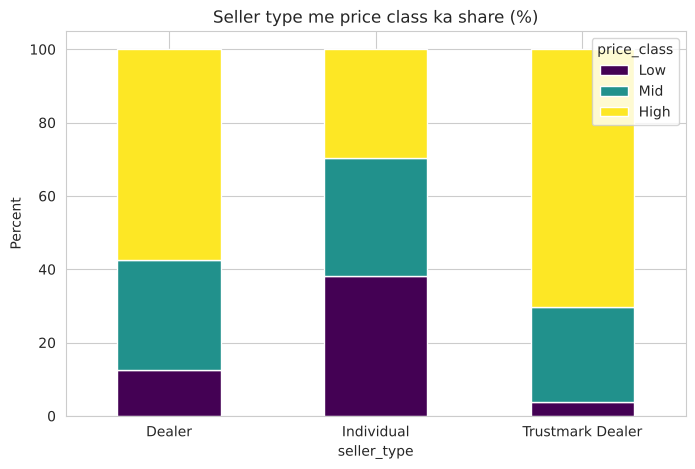

In [29]:
seller_share = pd.crosstab(df["seller_type"], df["price_class"], normalize="index") * 100
seller_share = seller_share[class_order]
print(seller_share.round(1))

seller_share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Seller type me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

**Observation (5.4):**
- Owner badalne par High class ka share girta hai: **First Owner 43.1%**, Second 18.7%, Third 8.8%, **Fourth & Above 3.0%**. Saath hi Low ka share badhta hai (23.5% se 72.8% tak).
- **Dealer** ki cars me **57.4%** High hain aur **Trustmark Dealer** me **70.4%**, jabki **Individual** sellers ki cars me sirf **29.6%** High hain.
- Trustmark Dealer ke data me sirf 27 cars hain, isliye us % par zyada bharosa nahi karna chahiye.
- Dhyan rakho: dealers aksar nayi aur kam owner wali cars bechte hain, isliye ye fark sirf seller type ki wajah se nahi hai.

## 6. Model ke liye data taiyar karna

Machine learning models sirf **numbers** samajhte hain, isliye:
1. Text columns ko numbers me badlenge (**encoding**)
2. Data ko **train** aur **test** me baatenge
3. Numeric features ko **scale** karenge (taaki sab ek jaise range me ho)

### 6.1 Encoding

In [30]:
# 1) Owner: order hai (1st, 2nd, 3rd...), isliye 1,2,3,4 number de do
owner_map = {"First Owner": 1, "Second Owner": 2, "Third Owner": 3, "Fourth & Above Owner": 4}
df["owner_num"] = df["owner"].map(owner_map)

# 2) Transmission: sirf 2 values hain -> 0 aur 1
df["transmission_num"] = df["transmission"].map({"Manual": 0, "Automatic": 1})

# 3) Brand: bahut saare brands hain, isliye top 10 rakho aur baaki ko "Other" bana do
top_brands = df["brand"].value_counts().head(10).index.tolist()

def group_brand(b):
    if b in top_brands:
        return b
    return "Other"

df["brand_group"] = df["brand"].apply(group_brand)

# 4) Fuel, seller_type, brand_group: one-hot encoding (har category ki alag 0/1 column)
dummies = pd.get_dummies(df[["fuel", "seller_type", "brand_group"]], drop_first=True)
dummies = dummies.astype(int)

print("One-hot columns:", dummies.shape[1])
dummies.head()

One-hot columns: 15


,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,brand_group_Ford,brand_group_Honda,brand_group_Hyundai,brand_group_Mahindra,brand_group_Maruti,brand_group_Other,brand_group_Renault,brand_group_Tata,brand_group_Toyota,brand_group_Volkswagen
0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0
1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
2,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0
3,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0


In [31]:
# Final features (X) aur target (y)
number_features = ["car_age", "km_driven", "mileage", "engine", "max_power",
                   "seats", "torque_nm", "km_per_year", "power_per_cc",
                   "owner_num", "transmission_num"]

X = pd.concat([df[number_features], dummies], axis=1)

# Target: Low=0, Mid=1, High=2
y = df["price_class"].map({"Low": 0, "Mid": 1, "High": 2})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", list(X.columns))

X shape: (6921, 26)
y shape: (6921,)
Features: ['car_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'km_per_year', 'power_per_cc', 'owner_num', 'transmission_num', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'brand_group_Ford', 'brand_group_Honda', 'brand_group_Hyundai', 'brand_group_Mahindra', 'brand_group_Maruti', 'brand_group_Other', 'brand_group_Renault', 'brand_group_Tata', 'brand_group_Toyota', 'brand_group_Volkswagen']


> ⚠️ **Important:** `selling_price` aur `price_lakh` ko features me **nahi** rakha, kyunki target isi se bana hai. Rakhte to model "cheat" kar leta (data leakage). `year` bhi nahi rakha kyunki `car_age` wahi information deta hai.

### 6.2 Train-Test split
80% data train ke liye, 20% test ke liye. `stratify=y` se teeno classes ka ratio dono me same rehta hai.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)
print("\nTrain class ratio:\n", y_train.value_counts(normalize=True).round(3))

Train size: (5536, 26)
Test size : (1385, 26)

Train class ratio:
 price_class
0    0.356
2    0.325
1    0.319
Name: proportion, dtype: float64


### 6.3 Scaling (StandardScaler)

`km_driven` lakho me hota hai, `seats` 2 se 10 me. KNN aur Logistic Regression jaise models bade numbers ko zyada importance de dete hain. **StandardScaler** har column ko mean = 0 aur std = 1 par le aata hai.

Scaler sirf **train data** par `fit` hota hai, phir train aur test dono par `transform`. Isse test data ki information model tak leak nahi hoti.

In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)     # train par seekho + badlo
X_test_scaled = scaler.transform(X_test)           # test par sirf badlo

# Pehle aur baad ka comparison (3 columns)
before = X_train[["km_driven", "engine", "max_power"]].describe().loc[["mean", "std"]]
after = pd.DataFrame(X_train_scaled, columns=X.columns)[["km_driven", "engine", "max_power"]].describe().loc[["mean", "std"]]

print("Scaling se PEHLE:\n", before.round(2), "\n")
print("Scaling ke BAAD:\n", after.round(2))

Scaling se PEHLE:
       km_driven   engine  max_power
mean   72758.05  1425.65      87.71
std    45854.44   485.63      31.16 

Scaling ke BAAD:
       km_driven  engine  max_power
mean        0.0     0.0        0.0
std         1.0     1.0        1.0


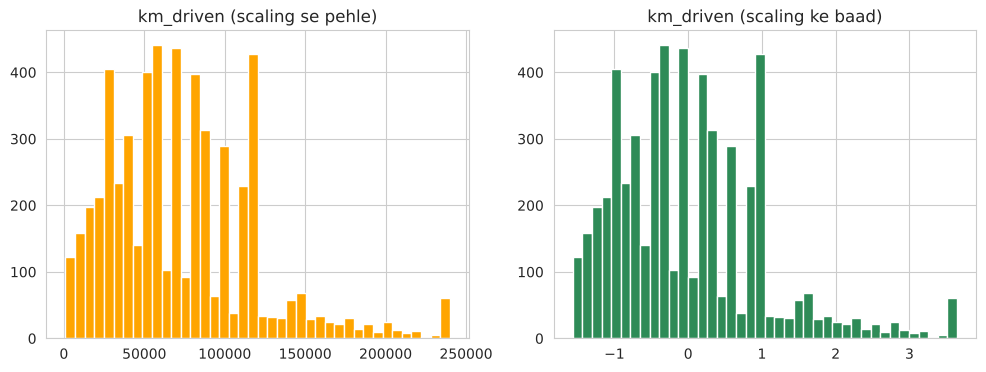

In [34]:
# Scaling ka visual effect (km_driven)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(X_train["km_driven"], bins=40, color="orange", edgecolor="white")
plt.title("km_driven (scaling se pehle)")

km_index = list(X.columns).index("km_driven")
plt.subplot(1, 2, 2)
plt.hist(X_train_scaled[:, km_index], bins=40, color="seagreen", edgecolor="white")
plt.title("km_driven (scaling ke baad)")

plt.show()

## 7. Machine Learning Models (Classification)

Hum 4 models train karenge:

| Model | Simple idea |
|---|---|
| **Logistic Regression** | Features ka weighted sum nikal kar har class ki probability batata hai |
| **KNN** | Naye car ke sabse paas ke K cars dekh kar unki majority class de deta hai |
| **Naive Bayes** | Bayes theorem + maanta hai ki saare features ek doosre se independent hain |
| **Random Forest** | Bahut saare decision trees ka group, sab vote karte hain |

### 7.1 KNN ke liye best K dhoondhna
K ki alag-alag values try karte hain aur **cross-validation** (train data ko 5 hisso me baant kar) se sabse achha K chunte hain. Test data yahan use nahi hota.

K = 1  CV accuracy = 0.7729
K = 3  CV accuracy = 0.7827
K = 5  CV accuracy = 0.7845


K = 7  CV accuracy = 0.7859
K = 9  CV accuracy = 0.7805


K = 11  CV accuracy = 0.7784
K = 15  CV accuracy = 0.7771


K = 21  CV accuracy = 0.769


K = 31  CV accuracy = 0.7558

Best K: 7


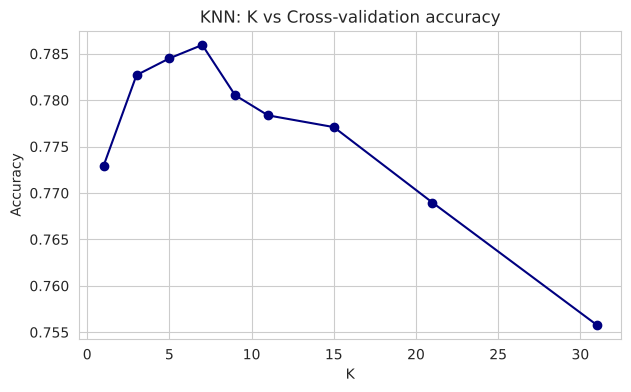

In [35]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy").mean()
    k_scores.append(score)
    print("K =", k, " CV accuracy =", round(score, 4))

best_k = k_values[k_scores.index(max(k_scores))]
print("\nBest K:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, k_scores, marker="o", color="navy")
plt.title("KNN: K vs Cross-validation accuracy")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.show()

### 7.2 Models train karna

Ek simple function banate hain jo kisi bhi model ko train kare aur uske scores save kare.

In [36]:
results = []          # saare models ke scores yahan jama honge
predictions = {}      # saare models ki test predictions

def evaluate_model(name, model):
    # 1) Train
    model.fit(X_train_scaled, y_train)

    # 2) Predict
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    # 3) Scores nikalo
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred, average="macro")
    recall = recall_score(y_test, test_pred, average="macro")
    f1 = f1_score(y_test, test_pred, average="macro")
    cv_acc = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy").mean()

    # 4) Save karo
    results.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "CV Accuracy": round(cv_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4)
    })
    predictions[name] = test_pred

    print(name, "-> Train:", round(train_acc, 3), "| Test:", round(test_acc, 3), "| F1:", round(f1, 3))

In [37]:
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
evaluate_model("Logistic Regression", log_model)

# Model 2: KNN (best K ke saath)
knn_model = KNeighborsClassifier(n_neighbors=best_k)
evaluate_model("KNN", knn_model)

# Model 3: Naive Bayes
nb_model = GaussianNB()
evaluate_model("Naive Bayes", nb_model)

# Model 4: Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
evaluate_model("Random Forest", rf_model)

Logistic Regression -> Train: 0.811 | Test: 0.819 | F1: 0.818


KNN -> Train: 0.843 | Test: 0.787 | F1: 0.786
Naive Bayes -> Train: 0.578 | Test: 0.578 | F1: 0.507


Random Forest -> Train: 0.99 | Test: 0.834 | F1: 0.832


## 8. Model Evaluation (Best Model)

**Metrics ka matlab:**
- **Accuracy:** kitne % predictions sahi the
- **Precision:** jab model ne "High" bola, to kitni baar wo sach me High thi
- **Recall:** jitni cars sach me High thi, unme se kitni model ne pakdi
- **F1-score:** Precision aur Recall ka balance (yahan *macro* average = teeno classes ko barabar importance)

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df

,Model,Train Accuracy,CV Accuracy,Test Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9897,0.8347,0.8339,0.8325,0.8321,0.8323
1,Logistic Regression,0.8109,0.8087,0.8195,0.8180,0.8175,0.8177
2,KNN,0.8427,0.7859,0.7870,0.7865,0.7853,0.7856
3,Naive Bayes,0.5777,0.5499,0.5783,0.5996,0.5722,0.5066


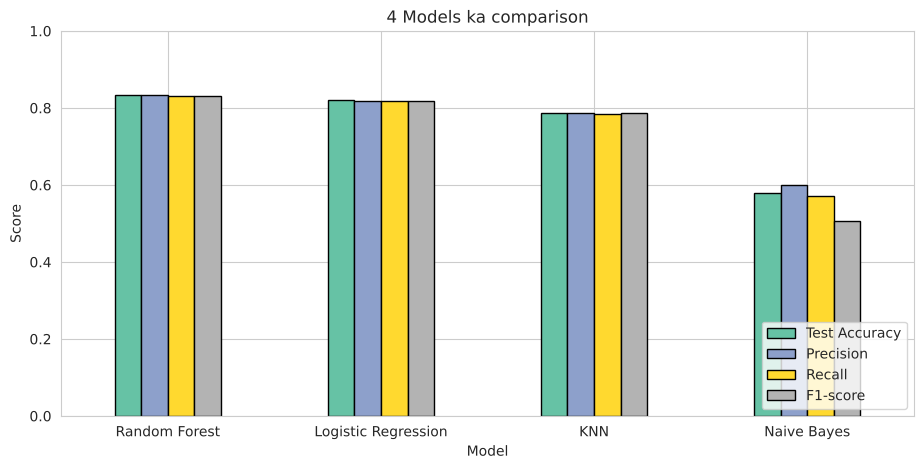

In [39]:
# Models ka comparison chart
metrics = ["Test Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df.set_index("Model")[metrics]

plot_df.plot(kind="bar", figsize=(11, 5), colormap="Set2", edgecolor="black")
plt.title("4 Models ka comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

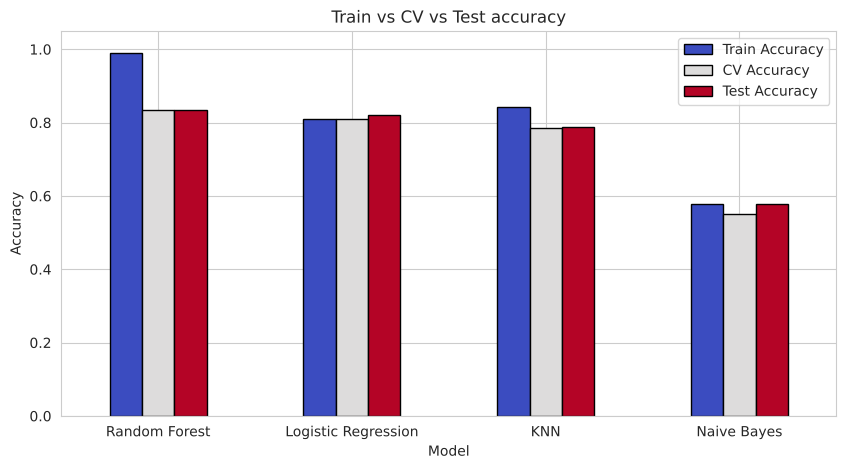

In [40]:
# Train vs Test accuracy (overfitting check)
check_df = results_df.set_index("Model")[["Train Accuracy", "CV Accuracy", "Test Accuracy"]]

check_df.plot(kind="bar", figsize=(10, 5), colormap="coolwarm", edgecolor="black")
plt.title("Train vs CV vs Test accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

**Overfitting kaise pehchane:** agar Train accuracy bahut zyada aur Test accuracy kaafi kam ho, to model ratta maar raha hai (overfitting). Gap jitna chhota, utna achha.

### 8.1 Confusion Matrix
Rows = asli class, Columns = model ki prediction. Diagonal par jitne zyada numbers, utna achha.

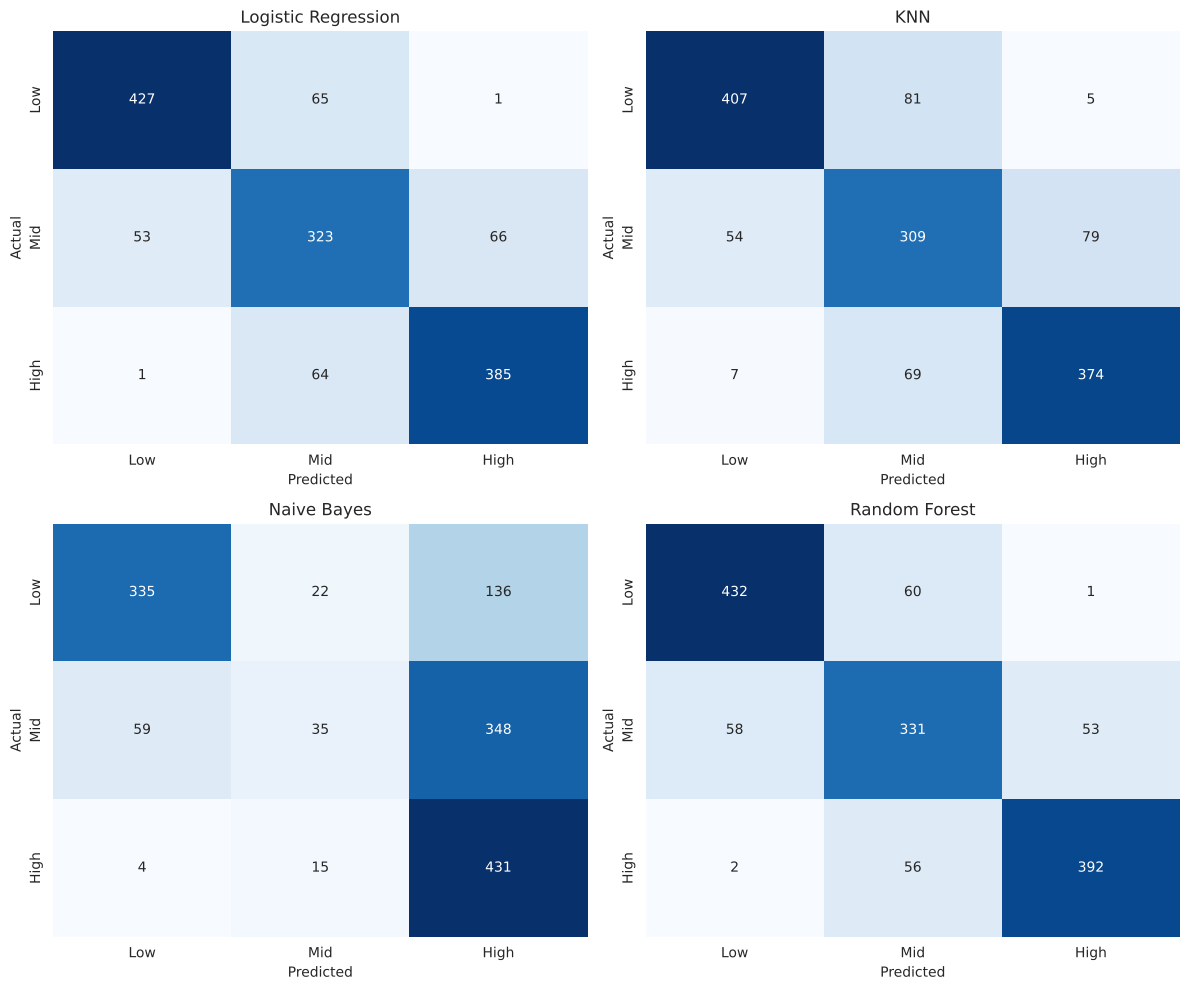

In [41]:
class_names = ["Low", "Mid", "High"]
model_names = ["Logistic Regression", "KNN", "Naive Bayes", "Random Forest"]

plt.figure(figsize=(12, 10))

for i in range(4):
    name = model_names[i]
    cm = confusion_matrix(y_test, predictions[name])
    plt.subplot(2, 2, i + 1)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 8.2 Best model ki detailed report

In [42]:
best_model_name = results_df.loc[0, "Model"]
print("BEST MODEL:", best_model_name)
print()
print(classification_report(y_test, predictions[best_model_name], target_names=class_names))

BEST MODEL: Random Forest

              precision    recall  f1-score   support

         Low       0.88      0.88      0.88       493
         Mid       0.74      0.75      0.74       442
        High       0.88      0.87      0.88       450

    accuracy                           0.83      1385
   macro avg       0.83      0.83      0.83      1385
weighted avg       0.83      0.83      0.83      1385



**Naive Bayes ka score kam kyun aaya?**
Naive Bayes ka **test accuracy 57.8%** aur **F1 0.51** aaya, jo baaki teeno models se bahut kam hai (phir bhi random guess ke 33% se behtar hai). Wajah:
1. **Independence assumption toot-ta hai:** NB maanta hai ki saare features ek doosre se independent hain. Par engine, max_power aur torque_nm aapas me strongly correlated hain, aur car_age aur km_driven bhi.
2. **Gaussian assumption:** GaussianNB har feature ko bell-curve (normal) maanta hai. Yahan km_driven jaise features skewed hain aur 0/1 one-hot columns normal distribution nahi hote.
3. Price in features ke **combination** se decide hota hai (power + age + brand sath me), jabki NB har feature ko alag-alag tolta hai.

Ye ek valid finding hai: **har model har data par achha nahi chalta.**

## 9. Objectives 1 to 5 (Classification models ke saath)

Ab hum apne models se objectives investigate karte hain.

**Tarika:** ek chhota function `test_models(features)` banate hain, jo sirf diye gaye features par **4 models train** karke unki **test accuracy** deta hai. Agar sirf kuch features se bhi accuracy **baseline** (hamesha sabse common class bolne wali accuracy) se kaafi upar jaati hai, to wo features class predict karne me kaam ke hain.

In [43]:
# Baseline: agar model hamesha sabse common class bole to accuracy kitni aayegi
baseline = round(y_test.value_counts(normalize=True).max(), 3)
print("Baseline accuracy:", baseline)

# Ek function: diye gaye features par 4 models train karke test accuracy dena
def test_models(feature_list):
    X_part = X[feature_list]
    X_tr, X_te, y_tr, y_te = train_test_split(X_part, y, test_size=0.2, random_state=42, stratify=y)

    sc = StandardScaler()
    X_tr = sc.fit_transform(X_tr)
    X_te = sc.transform(X_te)

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "KNN": KNeighborsClassifier(n_neighbors=best_k),
        "Naive Bayes": GaussianNB(),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
    }

    scores = {}
    for name in models:
        model = models[name]
        model.fit(X_tr, y_tr)
        scores[name] = round(accuracy_score(y_te, model.predict(X_te)), 3)
    return scores


# Feature groups
all_cols = list(X.columns)

fuel_cols = []
seller_cols = []
for col in all_cols:
    if col.startswith("fuel_"):
        fuel_cols.append(col)
    if col.startswith("seller_type_"):
        seller_cols.append(col)

print("Fuel columns  :", fuel_cols)
print("Seller columns:", seller_cols)

Baseline accuracy: 0.356
Fuel columns  : ['fuel_Diesel', 'fuel_LPG', 'fuel_Petrol']
Seller columns: ['seller_type_Individual', 'seller_type_Trustmark Dealer']


### 🎯 Objective 1: Kaun se features models ke hisaab se class predict karne me sabse important hain?
Do models se importance nikalte hain: **Random Forest** (feature importance) aur **Logistic Regression** (coefficients ka average absolute value; features scaled hain isliye comparable hain).

Random Forest top 10:
 car_age         0.225
torque_nm       0.115
max_power       0.111
km_driven       0.104
km_per_year     0.090
power_per_cc    0.079
mileage         0.068
engine          0.061
owner_num       0.037
seats           0.018
dtype: float64 

Logistic Regression top 10:
 car_age                2.558
engine                 1.688
fuel_Diesel            1.109
power_per_cc           1.080
brand_group_Maruti     0.978
brand_group_Hyundai    0.604
brand_group_Toyota     0.545
brand_group_Honda      0.462
mileage                0.337
brand_group_Ford       0.303
dtype: float64


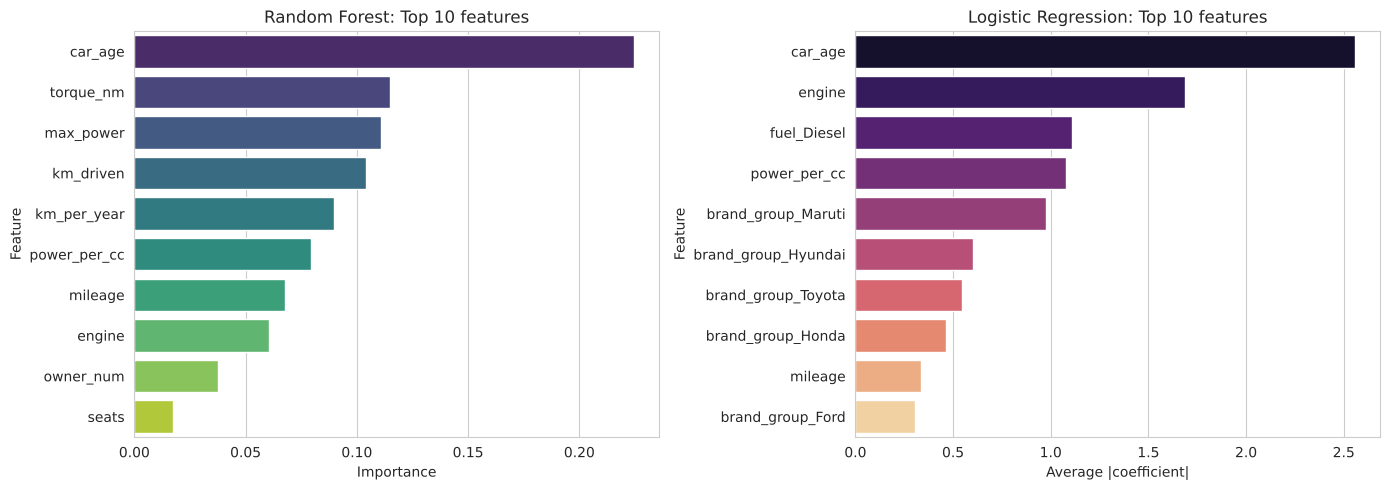

In [ ]:

# Random Forest ke hisaab se importance
rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
rf_top = rf_importance.sort_values(ascending=False).head(10)

# Logistic Regression ke hisaab se importance
lr_importance = pd.Series(np.abs(log_model.coef_).mean(axis=0), index=X.columns)
lr_top = lr_importance.sort_values(ascending=False).head(10)

print("Random Forest top 10:\n", rf_top.round(3), "\n")
print("Logistic Regression top 10:\n", lr_top.round(3))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(x=rf_top.values, y=rf_top.index, palette="viridis")
plt.title("Random Forest: Top 10 features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.subplot(1, 2, 2)
sns.barplot(x=lr_top.values, y=lr_top.index, palette="magma")
plt.title("Logistic Regression: Top 10 features")
plt.xlabel("Average |coefficient|")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**Observation (Objective 1):**
- **car_age** dono models ke hisaab se **sabse important** feature hai: Random Forest importance **0.225** (agle feature se lagbhag double) aur Logistic Regression me bhi sabse bada coefficient (2.56).
- Random Forest ke top features: **car_age (0.225)**, **torque_nm (0.115)**, **max_power (0.111)**, **km_driven (0.104)**.
- Logistic Regression ke top features: **car_age (2.56)**, **engine (1.69)**, **fuel_Diesel (1.11)**, **power_per_cc (1.08)**, phir brand columns (Maruti, Hyundai, Toyota...).
- Dono models me sirf car_age common top par hai. Fark ki wajah: engine, torque aur max_power aapas me strongly correlated hain, isliye Logistic Regression ka weight inme se kisi ek par zyada aa jaata hai. Random Forest ye weight inme baant deta hai.
- Matlab: **car ki age** class predict karne ka sabse bharose layak feature hai, aur uske baad car ki **power / engine / torque** wale features aate hain.

### 🎯 Objective 2: Sirf car age aur km_driven se models class kitni sahi predict kar paate hain?

In [45]:
rows = {}
rows["Only car_age"] = test_models(["car_age"])
rows["Only km_driven"] = test_models(["km_driven"])
rows["car_age + km_driven"] = test_models(["car_age", "km_driven"])
rows["All features"] = test_models(all_cols)

obj2_table = pd.DataFrame(rows).T
obj2_table

,Logistic Regression,KNN,Naive Bayes,Random Forest
Only car_age,0.621,0.478,0.615,0.619
Only km_driven,0.448,0.383,0.446,0.432
car_age + km_driven,0.621,0.601,0.610,0.597
All features,0.819,0.787,0.578,0.833


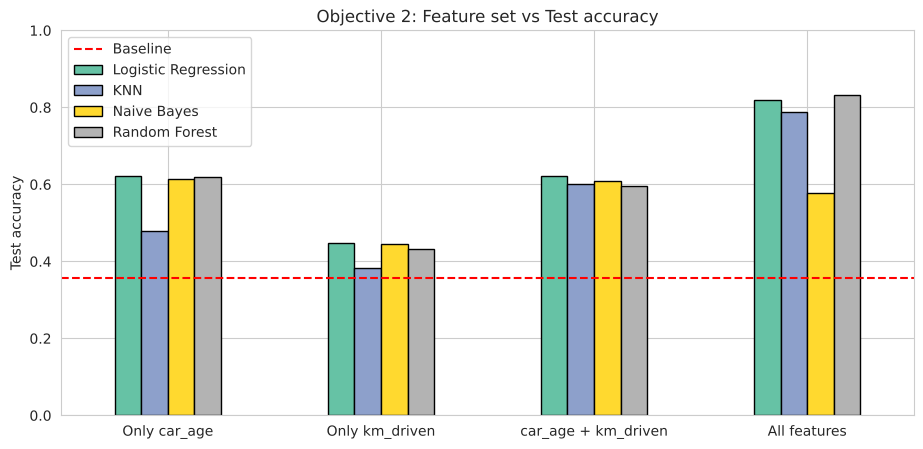

In [46]:
obj2_table.plot(kind="bar", figsize=(11, 5), colormap="Set2", edgecolor="black")
plt.axhline(baseline, color="red", linestyle="--", label="Baseline")
plt.title("Objective 2: Feature set vs Test accuracy")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper left")
plt.show()

**Observation (Objective 2):**
- Baseline (hamesha sabse common class bolna) accuracy **0.356** hai.
- Sirf **car_age** se hi Logistic Regression **0.621**, Naive Bayes **0.615** aur Random Forest **0.619** accuracy dete hain. Ye baseline se lagbhag **26 points** upar hai.
- Sirf **km_driven** se accuracy sirf **0.38 se 0.45** tak jaati hai, yaani car_age se kaafi kam.
- **car_age + km_driven** dono saath dene par bhi accuracy badhti nahi (Logistic Regression 0.621 hi rahi, aur KNN/Random Forest me 0.60 ke aaspaas). Matlab car_age pata ho to km_driven se alag se kuch khaas nahi milta.
- **All features** se accuracy badh kar **0.82 se 0.83** (Logistic Regression, Random Forest) ho jaati hai. Yaani age bahut kuch batati hai, par baaki features (power, engine, brand) se aur 20 points ka sudhar aata hai.
- Dhyan rakho: KNN ko ek ya do features par achha result nahi milta (car_age akele par 0.478).

### 🎯 Objective 3: Fuel type aur transmission model ki accuracy me kitna yogdan dete hain?
Do tarah se dekhte hain: (a) sirf in features se accuracy, (b) in features ko **hata** dene par poore model ki accuracy kitni girti hai.

In [47]:
fuel_trans_cols = fuel_cols + ["transmission_num"]

# Poore features me se fuel aur transmission hata do
without_ft = []
for col in all_cols:
    if col not in fuel_trans_cols:
        without_ft.append(col)

rows = {}
rows["Only fuel"] = test_models(fuel_cols)
rows["Only transmission"] = test_models(["transmission_num"])
rows["Fuel + transmission"] = test_models(fuel_trans_cols)
rows["All features"] = test_models(all_cols)
rows["All without fuel & transmission"] = test_models(without_ft)

obj3_table = pd.DataFrame(rows).T
obj3_table

,Logistic Regression,KNN,Naive Bayes,Random Forest
Only fuel,0.477,0.414,0.331,0.477
Only transmission,0.425,0.425,0.425,0.425
Fuel + transmission,0.498,0.370,0.331,0.498
All features,0.819,0.787,0.578,0.833
All without fuel & transmission,0.809,0.792,0.550,0.832


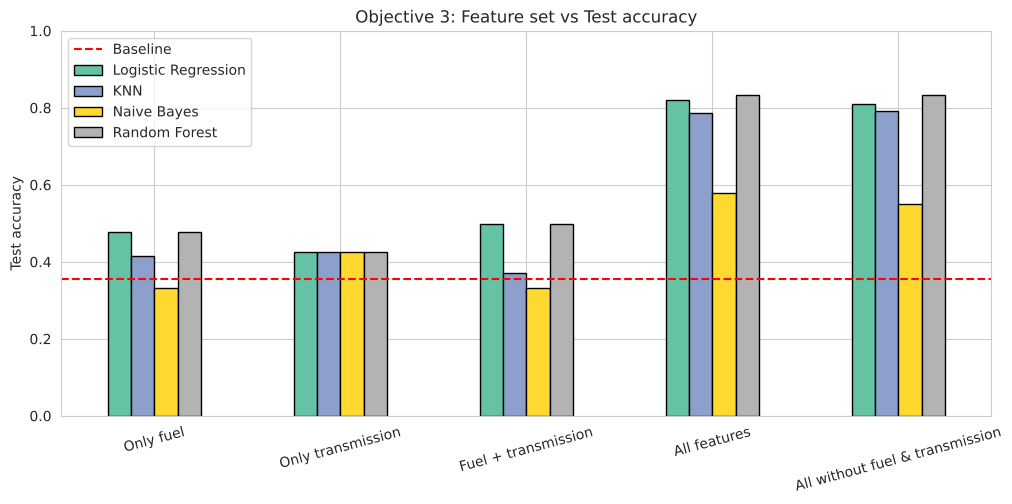

In [48]:
obj3_table.plot(kind="bar", figsize=(12, 5), colormap="Set2", edgecolor="black")
plt.axhline(baseline, color="red", linestyle="--", label="Baseline")
plt.title("Objective 3: Feature set vs Test accuracy")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="upper left")
plt.show()

**Observation (Objective 3):**
- Akele-akele ye features baseline (0.356) se upar jaate hain: **sirf fuel** se Logistic Regression/Random Forest **0.477**, **sirf transmission** se **0.425**, aur **dono saath** me **0.498**.
- Par jab baaki features maujood hon, to fuel aur transmission **hatane** par Random Forest ki accuracy **0.833 se 0.832** hi hoti hai (lagbhag koi fark nahi), aur Logistic Regression me bhi sirf 1 point ka fark hai (0.819 se 0.809).
- Matlab fuel aur transmission akele me thoda signal rakhte hain, par inki information age, engine aur power wale features me pehle se aa jaati hai. (Automatic cars aksar powerful aur nayi hoti hain.)
- Naive Bayes ke **sirf fuel** wale result (0.331) baseline se neeche hai, isliye wahan koi nateeja nahi nikalna chahiye.
- Dhyan rakho: test set me 1385 cars hain, isliye 1 point ke aaspaas ke farq ko noise samjho.

### 🎯 Objective 4: Owner count aur seller type model ki accuracy me kitna yogdan dete hain?

In [49]:
owner_seller_cols = ["owner_num"] + seller_cols

without_os = []
for col in all_cols:
    if col not in owner_seller_cols:
        without_os.append(col)

rows = {}
rows["Only owner"] = test_models(["owner_num"])
rows["Only seller type"] = test_models(seller_cols)
rows["Owner + seller type"] = test_models(owner_seller_cols)
rows["All features"] = test_models(all_cols)
rows["All without owner & seller type"] = test_models(without_os)

obj4_table = pd.DataFrame(rows).T
obj4_table

,Logistic Regression,KNN,Naive Bayes,Random Forest
Only owner,0.483,0.365,0.483,0.483
Only seller type,0.404,0.344,0.404,0.404
Owner + seller type,0.484,0.391,0.404,0.488
All features,0.819,0.787,0.578,0.833
All without owner & seller type,0.814,0.805,0.534,0.835


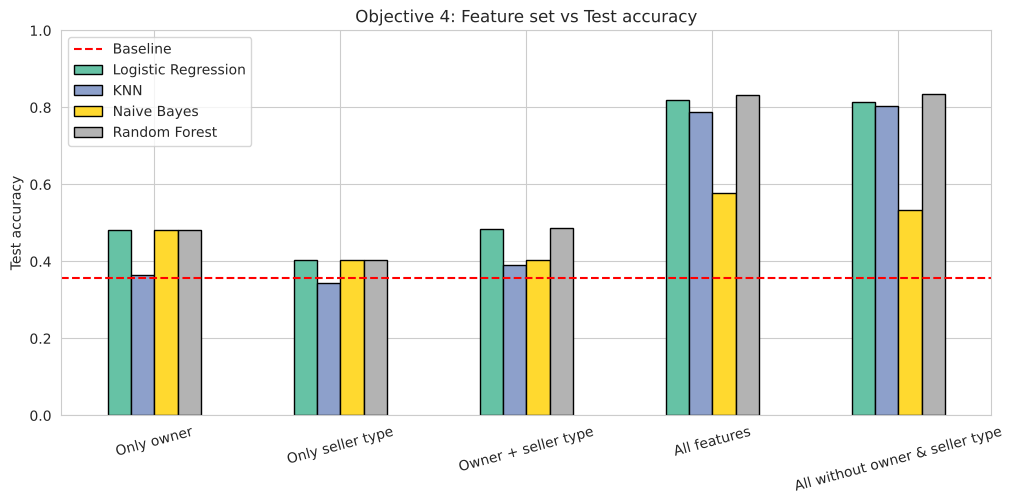

In [ ]:
obj4_table.plot(kind="bar", figsize=(12, 5), colormap="Set2", edgecolor="black")
plt.axhline(baseline, color="red", linestyle="--", label="Baseline")
plt.title("Objective 4: Feature set vs Test accuracy")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)


In [ ]:
plt.legend(loc="upper left")
plt.show()

**Observation (Objective 4):**
- **Sirf owner** se Logistic Regression, Naive Bayes aur Random Forest **0.483** accuracy dete hain, aur **sirf seller type** se **0.404**. Dono baseline (0.356) se upar hain.
- Par baaki features maujood hon to owner aur seller type **hatane** par Random Forest ki accuracy **0.833 se 0.835** ho jaati hai (thodi badhti hai), aur Logistic Regression me sirf 0.5 point kam (0.819 se 0.814).
- Matlab owner count ki information zyadatar car_age me aa jaati hai (purani cars ke owners zyada hote hain), aur seller type ka alag se koi bada yogdan nahi hai.
- Dhyan rakho: KNN ka sirf seller type par result (0.344) baseline se bhi kam hai, aur ye 1385 test cars wale ek hi split ka result hai.
- Seller type me Trustmark Dealer ki sirf 27 cars hain, isliye uska effect kam bharose layak hai.

### ✅ Objective 5: Best classification model kaun sa hai?
(Detail Section 8 me hai: metrics table, confusion matrix aur classification report.)

In [51]:
best_row = results_df.loc[0]
print("Best model       :", best_row["Model"])
print("Test accuracy    :", best_row["Test Accuracy"])
print("Macro F1-score   :", best_row["F1-score"])
print()
print("Ranking (F1 ke hisaab se):")
for i in range(len(results_df)):
    print(i + 1, ".", results_df.loc[i, "Model"], "-> F1 =", results_df.loc[i, "F1-score"])

Best model       : Random Forest
Test accuracy    : 0.8339
Macro F1-score   : 0.8323

Ranking (F1 ke hisaab se):
1 . Random Forest -> F1 = 0.8323
2 . Logistic Regression -> F1 = 0.8177
3 . KNN -> F1 = 0.7856
4 . Naive Bayes -> F1 = 0.5066


## 10. Key Findings, Conclusion aur Recommendations

### 📌 Key Findings
1. Dataset me **1,202 duplicate rows** (~15%) aur ~3% missing values thi, aur mileage/torque/engine/max_power text me alag-alag units me the. Cleaning ke baad **6,921 cars** bachi.
2. **Sabse important feature car_age hai:** class ke saath correlation −0.64 hai, Random Forest importance sabse upar (0.225) aur Logistic Regression ke coefficients me bhi sabse upar. Uske baad torque_nm, max_power aur km_driven (Random Forest ke hisaab se).
3. **Sirf car_age se hi 62% accuracy** milti hai (Logistic Regression 0.621), jabki baseline 35.6% hai. Sirf km_driven se 38% se 45%. car_age ke saath km_driven jodne se accuracy nahi badhti.
4. **Fuel, transmission, owner aur seller type** akele-akele baseline se upar accuracy dete hain (0.40 se 0.50), par baaki features ke hote hue inhe hatane se Random Forest ki accuracy lagbhag same rehti hai (0.833 se 0.832 aur 0.835). Inki information age, power aur engine me pehle se hai.
5. **EDA ke class shares:** 0-3 saal wali cars me 66.4% High hain, 10+ saal wali me 90.2% Low. Automatic me 74.0% High (Manual me 28.7%), First Owner me 43.1% High (Fourth & Above me 3.0%), Dealer me 57.4% High (Individual me 29.6%). Ye fark aksar age aur power ke saath mile hue hain.
6. **Model comparison (Test accuracy / Macro F1):**

| Model | Test Accuracy | Macro F1 |
|---|---|---|
| Random Forest | 0.834 | 0.832 |
| Logistic Regression | 0.820 | 0.818 |
| KNN (K=7) | 0.787 | 0.786 |
| Naive Bayes | 0.578 | 0.507 |

7. Teeno classes me **Mid** class predict karna sabse mushkil hai (F1 ~0.74), jabki Low aur High ka F1 ~0.88 hai. Ye natural hai kyunki Mid class dono taraf ki boundary ke beech hai.

### 🏁 Conclusion
**Random Forest sabse best model** nikla: test accuracy **83.4%** aur macro F1 **0.832**. Logistic Regression sirf thoda peeche hai (82.0%), jo ek simple aur fast model ke liye achha result hai. KNN 78.7% par raha, aur Naive Bayes 57.8% par sabse kamzor raha kyunki uske independence assumptions is data par fit nahi hote.

Random Forest ka **train accuracy 99%** hai jabki test 83%, yaani thoda overfitting hai. Phir bhi 5-fold CV (83.5%) aur test (83.4%) ek jaise hain, isliye result bharose layak hai. Logistic Regression ka train aur test accuracy lagbhag barabar hai (81% aur 82%), isliye wo zyada stable hai.

Overall, ek used car ka price segment (Low / Mid / High) uski **age, power, torque, km driven aur brand** dekh kar lagbhag 5 me se 4 baar sahi predict kiya ja sakta hai.

### 💡 Recommendations
**Buyers ke liye:**
- Budget kam ho to 7 saal ya usse purani car dekho: is group me zyadatar cars Low class me aati hain (7-10 saal me 53%, 10+ saal me 90%). 4-6 saal wali cars Mid/High me aati hain, to wahan value-for-money ke liye First Owner aur Manual car dhundho.
- Dealer se lene par car aksar nayi aur better condition ki milti hai (High class ka share zyada), par price bhi zyada hota hai. Individual se sasti car mil sakti hai, par inspection zaroor karwao.

**Sellers ke liye:**
- Car jaldi bechne se High class me aane ke chances zyada hote hain (0-3 saal me 66.4% High, 7-10 saal me sirf 10.1%).
- Kam owners aur kam km wali car ko zyada price milta hai, isliye service record aur ownership history saaf rakho.

**Dealers / platforms ke liye:**
- Random Forest model ko ek **quick price-segment estimator** ki tarah use kiya ja sakta hai (listing ko Low/Mid/High me daalne ke liye).
- Mid segment me model ki galti zyada hai, isliye wahan manual review ya zyada features (city, car condition) jodna chahiye.

**Model ke liye:**
- Random Forest ko `max_depth` ya `min_samples_leaf` se tune karke overfitting kam kiya ja sakta hai.

### ⚠️ Limitations
- Data 2020 tak ke cars ka snapshot hai, aaj ke market rates alag ho sakte hain.
- Price classes quantile se bani hain, isliye class ke edge par (boundary ke paas) wali cars me galti zyada hoti hai.
- Naive Bayes ke assumptions is data par fit nahi hote.
- Section 9 ke feature-subset results ek hi train-test split par hain, isliye 1 point ke aaspaas ke farq ko noise samjho.
- Missing values median/mode se bhari gayi hain (simple approach).

### 🔭 Future Work
- Price ko seedha predict karne ke liye **regression** models (Linear, Random Forest Regressor) try karna.
- `GridSearchCV` se Random Forest ke parameters tune karna.
- City/region jaisi columns jodna (agar data mile).

In [52]:
# Cleaned dataset save karo (project submission me dataset ke saath ye bhi laga sakte ho)
df.to_csv("cleaned_car_data.csv", index=False)
print("cleaned_car_data.csv save ho gayi. Shape:", df.shape)

cleaned_car_data.csv save ho gayi. Shape: (6921, 25)
